# 产品流程图

## 目标
将产品的用户旅程绘制为 7 环节流程图，直观展示"无感接入 + 有感干预"的设计逻辑。

## 输入
- 产品设计要点（见 `docs/product_design.md`）

## 输出
- `results/charts/product_flow.png`

## 对应方法
- 用户旅程节点梳理：触达 → 实名认证 → 获得额度 → 分期支付 → 24h 冷静期 → 还款提醒 → 结清

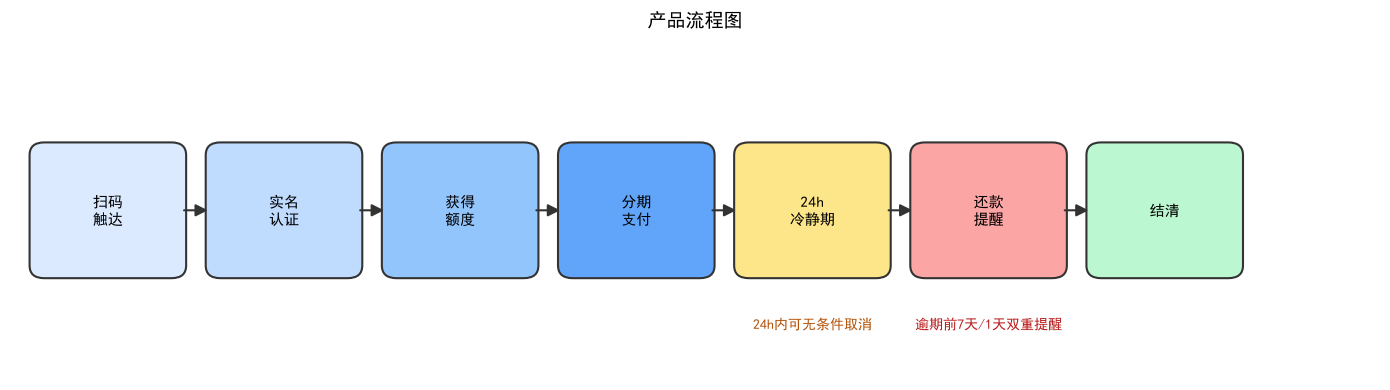

已保存： ..\results\charts\product_flow.png


In [1]:
# 产品流程图
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from pathlib import Path

matplotlib.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei']
matplotlib.rcParams['axes.unicode_minus'] = False

fig, ax = plt.subplots(figsize=(14, 4))
ax.set_xlim(0, 14)
ax.set_ylim(0, 4)
ax.axis("off")

# 7个节点
steps = [
    ("扫码\n触达", 1.0, "#dbeafe"),
    ("实名\n认证", 2.8, "#bfdbfe"),
    ("获得\n额度", 4.6, "#93c5fd"),
    ("分期\n支付", 6.4, "#60a5fa"),
    ("24h\n冷静期", 8.2, "#fde68a"),
    ("还款\n提醒", 10.0, "#fca5a5"),
    ("结清", 11.8, "#bbf7d0"),
]

box_w, box_h = 1.4, 1.4
y_center = 2.0

for text, x, color in steps:
    box = FancyBboxPatch(
        (x - box_w/2, y_center - box_h/2), box_w, box_h,
        boxstyle="round,pad=0.1,rounding_size=0.15",
        linewidth=1.5, edgecolor="#333333", facecolor=color
    )
    ax.add_patch(box)
    ax.text(x, y_center, text, ha="center", va="center", fontsize=11)

for i in range(len(steps) - 1):
    x_start = steps[i][1] + box_w/2
    x_end = steps[i+1][1] - box_w/2
    arrow = FancyArrowPatch(
        (x_start + 0.05, y_center), (x_end - 0.05, y_center),
        arrowstyle="-|>", mutation_scale=18,
        linewidth=1.5, color="#333333"
    )
    ax.add_patch(arrow)

# 冷静期下方的分支说明
ax.text(8.2, 0.6, "24h内可无条件取消", ha="center", fontsize=10, color="#b45309")
ax.text(10.0, 0.6, "逾期前7天/1天双重提醒", ha="center", fontsize=10, color="#b91c1c")

ax.set_title("产品流程图", fontsize=14, pad=10)

CHART_DIR = Path("../results/charts")
CHART_DIR.mkdir(parents=True, exist_ok=True)
plt.tight_layout()
plt.savefig(CHART_DIR / "product_flow.png", dpi=200, bbox_inches="tight")
plt.show()
print("已保存：", CHART_DIR / "product_flow.png")